# Step 1: Create the inventory

In [2]:
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path("../")
VIDEO_DIR = PROJECT_ROOT / "data" / "raw" / "dolos_clips"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_CSV = OUTPUT_DIR / "video_inventory.csv"

print("Project root:", PROJECT_ROOT)
print("Video directory:", VIDEO_DIR)
print("Video directory exists:", VIDEO_DIR.exists())

if not VIDEO_DIR.exists():
    raise FileNotFoundError(
        f"Can't find {VIDEO_DIR}. Set PROJECT_ROOT to the root of your project repository."
    )

Project root: ..
Video directory: ..\data\raw\dolos_clips
Video directory exists: True


In [3]:
# Find videos recursively and create one row per file.
video_paths = sorted(
    p for p in VIDEO_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() == ".mp4"
)

rows = []
for p in video_paths:
    rows.append({
        "clip_id": p.stem,
        "file_name": p.name,
        "relative_path": str(p.relative_to(PROJECT_ROOT)),
        "size_bytes": p.stat().st_size,
    })

inventory = pd.DataFrame(rows, columns=["clip_id", "file_name", "relative_path", "size_bytes"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
inventory.to_csv(OUTPUT_CSV, index=False)

print(f"Video files found: {len(inventory):,}")
print(f"Inventory saved to: {OUTPUT_CSV}")
inventory.head(15)

Video files found: 1,416
Inventory saved to: ..\data\processed\video_inventory.csv


,clip_id,file_name,relative_path,size_bytes
0,AN_WILTY_EP15_lie10,AN_WILTY_EP15_lie10.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie10.mp4,161959
1,AN_WILTY_EP15_lie11,AN_WILTY_EP15_lie11.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie11.mp4,177524
2,AN_WILTY_EP15_lie12,AN_WILTY_EP15_lie12.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie12.mp4,237247
3,AN_WILTY_EP15_lie13,AN_WILTY_EP15_lie13.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie13.mp4,227258
4,AN_WILTY_EP15_lie14,AN_WILTY_EP15_lie14.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie14.mp4,328568
5,AN_WILTY_EP15_lie15,AN_WILTY_EP15_lie15.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie15.mp4,215926
6,AN_WILTY_EP15_lie16,AN_WILTY_EP15_lie16.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie16.mp4,380515
7,AN_WILTY_EP15_lie17,AN_WILTY_EP15_lie17.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie17.mp4,337405
8,AN_WILTY_EP15_lie18,AN_WILTY_EP15_lie18.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie18.mp4,222255
9,AN_WILTY_EP15_lie19,AN_WILTY_EP15_lie19.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie19.mp4,152471


In [4]:
# Check duplicate IDs / names. These are warnings to investigate, not automatic errors.
if inventory.empty:
    print("WARNING: no .mp4 files were found.")
else:
    duplicate_stems = inventory[inventory["clip_id"].duplicated(keep=False)].sort_values("clip_id")
    duplicate_names = inventory[inventory["file_name"].duplicated(keep=False)].sort_values("file_name")
    zero_byte = inventory[inventory["size_bytes"] == 0]

    print("Unique clip IDs:", inventory["clip_id"].nunique())
    print("Duplicate clip IDs:", len(duplicate_stems))
    print("Duplicate filenames:", len(duplicate_names))
    print("Zero-byte files:", len(zero_byte))

    if not duplicate_stems.empty:
        display(duplicate_stems)
    if not zero_byte.empty:
        display(zero_byte)

Unique clip IDs: 1416
Duplicate clip IDs: 0
Duplicate filenames: 0
Zero-byte files: 0


In [5]:
# Search common project folders for likely metadata/annotation files.
# This only lists candidates; it does not assume a file is the correct annotation source.
metadata_extensions = {".xlsx", ".xls", ".csv", ".tsv", ".txt", ".json", ".jsonl"}
search_roots = [PROJECT_ROOT / "data", PROJECT_ROOT / "configs"]
metadata_candidates = []
for root in search_roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and p.suffix.lower() in metadata_extensions:
                metadata_candidates.append({
                    "file_name": p.name,
                    "relative_path": str(p.relative_to(PROJECT_ROOT)),
                    "size_bytes": p.stat().st_size,
                })

metadata_df = pd.DataFrame(metadata_candidates)
if metadata_df.empty:
    print("No likely metadata files found under data/ or configs/.")
    print("Next action: retrieve the official DOLOS annotation/metadata package.")
else:
    display(metadata_df.sort_values("relative_path"))

,file_name,relative_path,size_bytes
0,video_inventory.csv,data\processed\video_inventory.csv,139896
1,subject_isolated_splits.csv,data\splits\subject_isolated_splits.csv,169142


# Step 2: Split and Extract audio

In [6]:
from pathlib import Path
import av , pandas as pd

CLIPS_DIR = Path("../data/raw/dolos_clips")
rows = []
for p in sorted(CLIPS_DIR.glob("*.mp4")):
    try:
        with av.open(str(p)) as c: d = c.duration / 1e6
    except Exception:
        d = float("nan")
    rows.append((p.stem.replace(" ", ""), d))
dur_df = pd.DataFrame(rows, columns=["clip_id", "dur_s"])
print(dur_df.dur_s.describe().round(1))
print((dur_df.dur_s > 15).sum(), "clips > 15 s |", (dur_df.dur_s > 45).sum(), "clips > 45 s")
print(dur_df.nlargest(20, "dur_s"))

count    1416.0
mean        5.6
std        10.0
min         2.0
25%         4.0
50%         5.0
75%         6.0
max       300.0
Name: dur_s, dtype: float64
10 clips > 15 s | 4 clips > 45 s
                      clip_id       dur_s
698       LS_WILTY_EP3_truth5  300.000000
394      BRI_WILTY_EP61_lie_6  181.000000
170      AN_WILTY_EP22_truth1  123.000000
815        LS_WILTY_EP75_lie2   48.000000
390     BRI_WILTY_EP61_lie_36   41.000000
817        LS_WILTY_EP75_lie4   32.000000
808       LS_WILTY_EP73_true5   23.000000
829       LS_WILTY_EP76_lie14   22.000000
972        SB_WILTY_EP34_lie8   19.000000
1070      SB_WILTY_EP42_lie15   16.000000
955        SB_WILTY_EP33_lie5   14.000000
1043     SB_WILTY_EP38_truth3   14.000000
775        LS_WILTY_EP72_lie6   12.000000
1025    SB_WILTY_EP37_truth13   12.000000
1038       SB_WILTY_EP38_lie4   12.000000
1088    SB_WILTY_EP42_truth14   12.000000
519   BRI_WILTY_EP66_truth_15   11.020835
780       LS_WILTY_EP72_true2   11.000000
796       LS_

In [7]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit


INPUT_CSV = Path("../data/processed/video_inventory.csv")
OUTPUT_CSV = Path("../data/splits/subject_isolated_splits.csv")

def create_zero_leakage_splits():
    # 1. Load the dataset
    df = pd.read_csv(INPUT_CSV)
    
    # 2. Extract Subject Identity
    # Converts 'AN_WILTY_EP15_lie10' -> 'AN_WILTY_EP15'
    df['subject_id'] = df['clip_id'].apply(lambda x: "_".join(str(x).split('_')[:-1]))
    
    print(f"Total Clips: {len(df)}")
    print(f"Unique Subjects/Episodes: {df['subject_id'].nunique()}")

    # 3. First Split: Separate Train (70%) vs Temp (30%)
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
    train_idx, temp_idx = next(gss1.split(df, groups=df['subject_id']))
    
    # 4. Second Split: Separate Temp into Val (15%) and Test (15%)
    temp_df = df.iloc[temp_idx].copy()
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
    val_idx_temp, test_idx_temp = next(gss2.split(temp_df, groups=temp_df['subject_id']))
    
    # Map temp indices back to original dataframe
    val_idx = temp_idx[val_idx_temp]
    test_idx = temp_idx[test_idx_temp]

    # Assign split labels
    df.loc[train_idx, 'split'] = 'train'
    df.loc[val_idx, 'split'] = 'val'
    df.loc[test_idx, 'split'] = 'test'

    # Display split statistics
    print("\n--- Split Statistics ---")
    print(df['split'].value_counts())
    print("\n--- Unique Subjects per Split ---")
    print(df.groupby('split')['subject_id'].nunique())

    # Save mapping
    OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\nZero-leakage splits saved to: {OUTPUT_CSV}")

if __name__ == "__main__":
    create_zero_leakage_splits()

Total Clips: 1416
Unique Subjects/Episodes: 77

--- Split Statistics ---
split
train    1017
test      200
val       199
Name: count, dtype: int64

--- Unique Subjects per Split ---
split
test     12
train    53
val      12
Name: subject_id, dtype: int64

Zero-leakage splits saved to: ..\data\splits\subject_isolated_splits.csv


In [8]:
import pandas as pd
df = pd.read_csv(OUTPUT_CSV)
train_df = df[df['split'] == 'train'].copy()
print(f"EDA restricted to {len(train_df)} training clips.")

EDA restricted to 1017 training clips.


## Extracting audio

In [9]:
from pathlib import Path
import subprocess
import pandas as pd
import soundfile as sf 

PROJECT_ROOT = Path("../")
SPLITS_CSV = PROJECT_ROOT / "data" / "splits" / "subject_isolated_splits.csv"
AUDIO_TRAIN_DIR = PROJECT_ROOT / "data" / "processed" / "audio_train"
AUDIO_TRAIN_DIR.mkdir(parents=True, exist_ok=True)

# Load split dataset and filter strictly for training subjects
df = pd.read_csv(SPLITS_CSV)
train_df = df[df['split'] == 'train'].copy()

audio_metadata = []
print(f"Extracting and inspecting audio streams for {len(train_df)} training clips...")

for _, row in train_df.iterrows():
    clip_id = row['clip_id']
    video_path = PROJECT_ROOT / row['relative_path']
    wav_output_path = AUDIO_TRAIN_DIR / f"{clip_id}.wav"
    
    try:
        # Step 1: Extract audio using a direct ffmpeg subprocess command (if it doesn't already exist)
        if not wav_output_path.exists():
            cmd = [
                "ffmpeg", "-y", 
                "-i", str(video_path), 
                "-ar", "16000",       # Resample to 16kHz standard
                "-ac", "1",           # Convert to mono
                "-vn",                # Drop video stream
                str(wav_output_path)
            ]
            subprocess.run(cmd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)
            
        # Step 2: Read WAV properties using soundfile for clean EDA metadata collection
        if wav_output_path.exists():
            info = sf.info(str(wav_output_path))
            sample_rate = info.samplerate
            channels = info.channels
            duration_sec = info.duration
            num_samples = info.frames
            
            audio_metadata.append({
                "clip_id": clip_id,
                "audio_path": str(wav_output_path.relative_to(PROJECT_ROOT)),
                "sample_rate": sample_rate,
                "channels": channels,
                "duration_sec": duration_sec,
                "num_samples": num_samples
            })
    except Exception as e:
        print(f"Error processing audio for {clip_id}: {e}")

# Create summary DataFrame for your acoustic EDA notebook
audio_eda_df = pd.DataFrame(audio_metadata)
print(f"\nSuccessfully processed {len(audio_eda_df)} training audio files to `{AUDIO_TRAIN_DIR}`.")

Extracting and inspecting audio streams for 1017 training clips...

Successfully processed 1017 training audio files to `..\data\processed\audio_train`.


# Step 3: EDA

- All 1,017 training clips are 16 kHz mono, so sample rate and channels are constant. This follows from the extraction settings and carries no information.
- Clips are short and uniform: the median is 5 s and the middle half runs 4–6 s, with a minimum of 2 s.
- The mean (5.83 s) is far from the median, and the standard deviation (11.7 s) is larger than the mean. A few very long clips cause this; the longest is 300 s.

In [10]:
display(audio_eda_df.describe())

,sample_rate,channels,duration_sec,num_samples
count,1017.0,1017.0,1017.000000,1.017000e+03
mean,16000.0,1.0,5.834808,9.335693e+04
std,0.0,0.0,11.714545,1.874327e+05
min,16000.0,1.0,2.000000,3.200000e+04
25%,16000.0,1.0,4.000000,6.400000e+04
50%,16000.0,1.0,5.000000,8.000000e+04
75%,16000.0,1.0,6.000000,9.600000e+04
max,16000.0,1.0,300.000000,4.800000e+06


## RMS Energy & Amplitude Profiling

- Frames in the top 80% of energy ("active") average an RMS of 0.083. The bottom 20% ("silent baseline") average 0.010, about 8× lower.
- The sharp edge of the silent-baseline curve at about 0.02 is the 20th-percentile threshold I applied. It is not a natural boundary in the data.
- The silent baseline is not near zero. The recordings therefore always contain background sound (room, audience or music), not digital silence.
- The active distribution has a long right tail (up to about 0.4). Some frames are much louder than typical speech, possibly laughter, applause or raised voices.


computing RMS energy and peak amplitudes for 1017 training audio clips
Mean RMS Energy (Active Speech): 0.0827
Mean RMS Energy (Silent Baseline): 0.0101


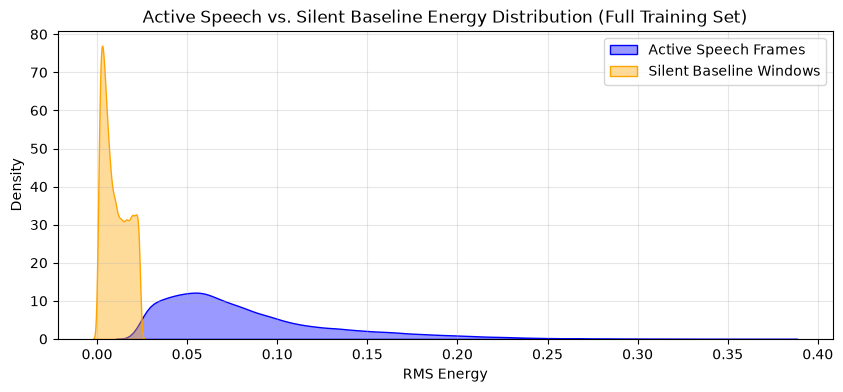

In [11]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

audio_dir = PROJECT_ROOT / "data" / "processed" / "audio_train"

rms_values = []
peak_amplitudes = []

print(f"computing RMS energy and peak amplitudes for {len(audio_eda_df)} training audio clips")
for _, row in audio_eda_df.iterrows(): 
    wav_path = audio_dir / f"{row['clip_id']}.wav"
    if wav_path.exists():
        y, sr = librosa.load(str(wav_path), sr=16000)
        
        # Compute Root Mean Square (RMS) energy across frames
        rms = librosa.feature.rms(y=y)[0]
        rms_values.extend(rms)
        peak_amplitudes.append(np.max(np.abs(y)))

rms_values = np.array(rms_values)

# Active speech vs Silent thresholding (using dynamic energy percentiles)
silence_threshold = np.percentile(rms_values, 20)
active_speech = rms_values[rms_values > silence_threshold]
silent_windows = rms_values[rms_values <= silence_threshold]

print(f"Mean RMS Energy (Active Speech): {np.mean(active_speech):.4f}")
print(f"Mean RMS Energy (Silent Baseline): {np.mean(silent_windows):.4f}")

# Plotting Energy Distribution
plt.figure(figsize=(10, 4))
sns.kdeplot(active_speech, label='Active Speech Frames', fill=True, color='blue', alpha=0.4)
sns.kdeplot(silent_windows, label='Silent Baseline Windows', fill=True, color='orange', alpha=0.4)
plt.title("Active Speech vs. Silent Baseline Energy Distribution (Full Training Set)")
plt.xlabel("RMS Energy")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## SNR & Clipping Inspection

- No clip contains samples at or above 0.99, so there is no hard clipping and no declipping is needed.
- The estimated SNR is about 30.6 ± 5.1 dB, roughly bell-shaped between 18 and 47 dB.
- No clip is extremely noisy. The ±5 dB spread shows that recording conditions vary between clips.
- *Limitation:* the SNR method (10th percentile of squared samples) overestimates SNR. Use the values to compare clips with each other, not as absolute SNR.


running SNR and clipping analysis across 1017 training audio clips
Clips with potential clipping (distortion): 0 out of 1017 training clips.
Estimated SNR (dB) - Mean: 30.58 dB | Std: 5.05 dB


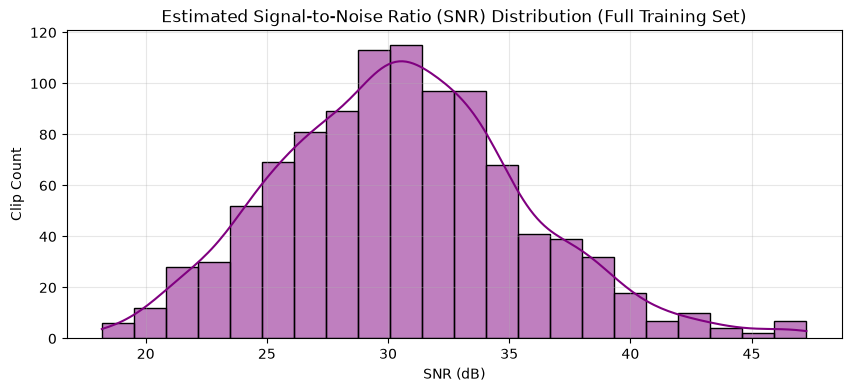

In [12]:
snr_estimates = []
clipping_counts = 0

print(f"running SNR and clipping analysis across {len(audio_eda_df)} training audio clips")
for _, row in audio_eda_df.iterrows():
    wav_path = audio_dir / f"{row['clip_id']}.wav"
    if wav_path.exists():
        y, sr = librosa.load(str(wav_path), sr=16000)
        
        # Check for clipping (amplitude >= 0.99)
        if np.any(np.abs(y) >= 0.99):
            clipping_counts += 1
            
        # Approximate SNR estimation using signal power vs noise floor estimation
        signal_power = np.mean(y**2)
        noise_floor = np.percentile(y**2, 10) # bottom 10% energy as noise floor approximation
        if noise_floor > 0:
            snr = 10 * np.log10(signal_power / noise_floor)
            snr_estimates.append(snr)

print(f"Clips with potential clipping (distortion): {clipping_counts} out of {len(audio_eda_df)} training clips.")
print(f"Estimated SNR (dB) - Mean: {np.mean(snr_estimates):.2f} dB | Std: {np.std(snr_estimates):.2f} dB")

plt.figure(figsize=(10, 4))
sns.histplot(snr_estimates, kde=True, color='purple')
plt.title("Estimated Signal-to-Noise Ratio (SNR) Distribution (Full Training Set)")
plt.xlabel("SNR (dB)")
plt.ylabel("Clip Count")
plt.grid(True, alpha=0.3)
plt.show()

## Global Normalization Statistics

- With all clips, the log-mel statistics are μ = −1.804 and σ = 3.317.
- σ is large because the log-mel values span everything from background noise to loud speech.


In [13]:
import torch
import torchaudio.transforms as T
import soundfile as sf

print(f"computing global normalization parameters (mean & std) for log-mel spectrograms across all {len(audio_eda_df)} training clips")

mel_transform = T.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    hop_length=533,  
    n_mels=128      
)

all_mels = []
for _, row in audio_eda_df.iterrows():
    wav_path = audio_dir / f"{row['clip_id']}.wav"
    if wav_path.exists():
        # Read using soundfile to completely avoid torchcodec backend issues
        y, sr = sf.read(str(wav_path))
        
        # Convert NumPy array to PyTorch tensor and adjust shape to (channels, time)
        waveform = torch.tensor(y, dtype=torch.float32)
        if waveform.ndim == 1:
            waveform = waveform.unsqueeze(0)  # Shape: (1, time) for mono
        else:
            waveform = waveform.t()          # Shape: (channels, time) if multi-channel
            
        mel_spec = mel_transform(waveform)
        log_mel = torch.log(mel_spec + 1e-9)
        all_mels.append(log_mel)

# Concatenate along time axis to compute global mean and std
concat_mels = torch.cat(all_mels, dim=-1)
global_mean = concat_mels.mean().item()
global_std = concat_mels.std().item()

print(f"Computed Training Log-Mel Mean (mu): {global_mean:.4f}")
print(f"Computed Training Log-Mel Std (sigma): {global_std:.4f}")

computing global normalization parameters (mean & std) for log-mel spectrograms across all 1017 training clips
Computed Training Log-Mel Mean (mu): -1.8038
Computed Training Log-Mel Std (sigma): 3.3174


## Removing outliers from the dataset

- Three clips are longer than 60 s: 123 s, 181 s and 300 s (`AN_WILTY_EP22_truth1`, `BRI_WILTY_EP61_lie_6`, `LS_WILTY_EP3_truth5`).
- Together they are about 604 s, roughly 10% of all training audio, from only 0.3% of the clips.
- They were removed from the training partition, leaving 1,014 clips.


In [14]:
import torch
import torchaudio.transforms as T
import soundfile as sf

# Identify and remove outliers (> 60 seconds) from audio_eda_df
outliers = audio_eda_df[audio_eda_df['duration_sec'] > 60.0]
print(f"Found {len(outliers)} outlier clip(s) to remove:")
display(outliers[['clip_id', 'duration_sec']])

# Delete outlier .wav files from disk
for _, row in outliers.iterrows():
    wav_path = PROJECT_ROOT / row['audio_path']
    if wav_path.exists():
        wav_path.unlink()
        print(f"Deleted outlier file: {wav_path.name}")

# Filter audio_eda_df to keep only valid clean clips
audio_eda_df = audio_eda_df[audio_eda_df['duration_sec'] <= 60.0].reset_index(drop=True)
print(f"\nClean training partition size: {len(audio_eda_df)} clips remaining.")

Found 3 outlier clip(s) to remove:


,clip_id,duration_sec
109,AN_WILTY_EP22_truth1,123.0
253,BRI_WILTY_EP61_lie_6,181.0
437,LS_WILTY_EP3_truth5,300.0


Deleted outlier file: AN_WILTY_EP22_truth1.wav
Deleted outlier file: BRI_WILTY_EP61_lie_6.wav
Deleted outlier file: LS_WILTY_EP3_truth5.wav

Clean training partition size: 1014 clips remaining.


### Re-computing global normalization parameters

In [15]:
mel_transform = T.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    hop_length=533,  
    n_mels=128      
)

all_mels = []
for _, row in audio_eda_df.iterrows():
    wav_path = PROJECT_ROOT / row['audio_path']
    if wav_path.exists():
        y, sr = sf.read(str(wav_path))
        waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0)  # Shape: (1, time)
        
        mel_spec = mel_transform(waveform)
        log_mel = torch.log(mel_spec + 1e-9)
        all_mels.append(log_mel)

# Concatenate along time axis to compute clean global stats
concat_mels = torch.cat(all_mels, dim=-1)
global_mean = concat_mels.mean().item()
global_std = concat_mels.std().item()

print(f"Computed Clean Training Log-Mel Mean (mu): {global_mean:.4f}")
print(f"Computed Clean Training Log-Mel Std (sigma): {global_std:.4f}")

Computed Clean Training Log-Mel Mean (mu): -1.9857
Computed Clean Training Log-Mel Std (sigma): 3.2916


### Re-computing RMS, Amplitude, SNR & Clipping

| Metric | Before | After |
|---|---|---|
| Log-mel μ | −1.804 | −1.986 |
| Log-mel σ | 3.317 | 3.292 |
| Active RMS | 0.0827 | 0.0779 |
| Silent-baseline RMS | 0.0101 | 0.0093 |
| SNR (mean ± SD) | 30.58 ± 5.05 dB | 30.59 ± 5.06 dB |
| Clipped clips | 0 | 0 |

- The three clips were louder than average. Removing them lowered the mean energy by about 6% and shifted the log-mel mean by 0.18.
- SNR is computed per clip, so it did not change.
- The cleaned statistics (μ = −1.986, σ = 3.292) are the ones to use for normalization.


===  ACROSS ALL 1014 CLEAN TRAINING CLIPS ===

--- Cleaned Energy Metrics ---
Mean RMS Energy (Active Speech): 0.0779
Mean RMS Energy (Silent Baseline): 0.0093

--- Cleaned Signal Quality Metrics ---
Clips with potential clipping: 0 out of 1014 clips.
Estimated SNR (dB) - Mean: 30.59 dB | Std: 5.06 dB


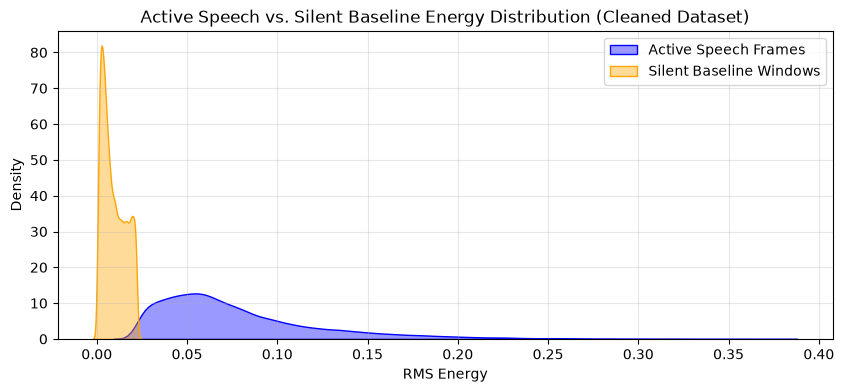

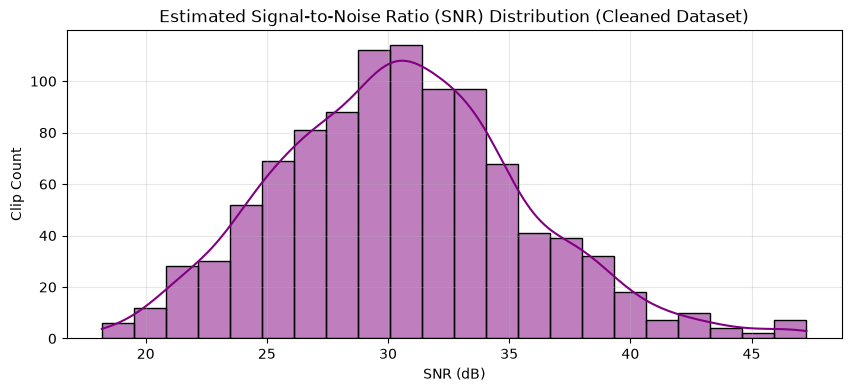

In [16]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

audio_dir = PROJECT_ROOT / "data" / "processed" / "audio_train"

rms_values = []
peak_amplitudes = []
snr_estimates = []
clipping_counts = 0

print(f"===  ACROSS ALL {len(audio_eda_df)} CLEAN TRAINING CLIPS ===")

for _, row in audio_eda_df.iterrows():
    wav_path = audio_dir / f"{row['clip_id']}.wav"
    if wav_path.exists():
        y, sr = librosa.load(str(wav_path), sr=16000)
        
        # 1. RMS Energy & Peak Amplitude
        rms = librosa.feature.rms(y=y)[0]
        rms_values.extend(rms)
        peak_amplitudes.append(np.max(np.abs(y)))
        
        # 2. Clipping check (amplitude >= 0.99)
        if np.any(np.abs(y) >= 0.99):
            clipping_counts += 1
            
        # 3. SNR estimation using signal power vs noise floor estimation (bottom 10% energy)
        signal_power = np.mean(y**2)
        noise_floor = np.percentile(y**2, 10)
        if noise_floor > 0:
            snr = 10 * np.log10(signal_power / noise_floor)
            snr_estimates.append(snr)

rms_values = np.array(rms_values)
snr_estimates = np.array(snr_estimates)

# Active speech vs Silent thresholding (using dynamic energy percentiles)
silence_threshold = np.percentile(rms_values, 20)
active_speech = rms_values[rms_values > silence_threshold]
silent_windows = rms_values[rms_values <= silence_threshold]

print(f"\n--- Cleaned Energy Metrics ---")
print(f"Mean RMS Energy (Active Speech): {np.mean(active_speech):.4f}")
print(f"Mean RMS Energy (Silent Baseline): {np.mean(silent_windows):.4f}")

print(f"\n--- Cleaned Signal Quality Metrics ---")
print(f"Clips with potential clipping: {clipping_counts} out of {len(audio_eda_df)} clips.")
print(f"Estimated SNR (dB) - Mean: {np.mean(snr_estimates):.2f} dB | Std: {np.std(snr_estimates):.2f} dB")

# --- Plot 1: Active Speech vs. Silent Baseline Energy Distribution ---
plt.figure(figsize=(10, 4))
sns.kdeplot(active_speech, label='Active Speech Frames', fill=True, color='blue', alpha=0.4)
sns.kdeplot(silent_windows, label='Silent Baseline Windows', fill=True, color='orange', alpha=0.4)
plt.title("Active Speech vs. Silent Baseline Energy Distribution (Cleaned Dataset)")
plt.xlabel("RMS Energy")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- Plot 2: Estimated Signal-to-Noise Ratio (SNR) Distribution ---
plt.figure(figsize=(10, 4))
sns.histplot(snr_estimates, kde=True, color='purple')
plt.title("Estimated Signal-to-Noise Ratio (SNR) Distribution (Cleaned Dataset)")
plt.xlabel("SNR (dB)")
plt.ylabel("Clip Count")
plt.grid(True, alpha=0.3)
plt.show()

Using direct parameters -> Sample Rate: 16000 Hz, N_Mels: 128, Hop Length: 533


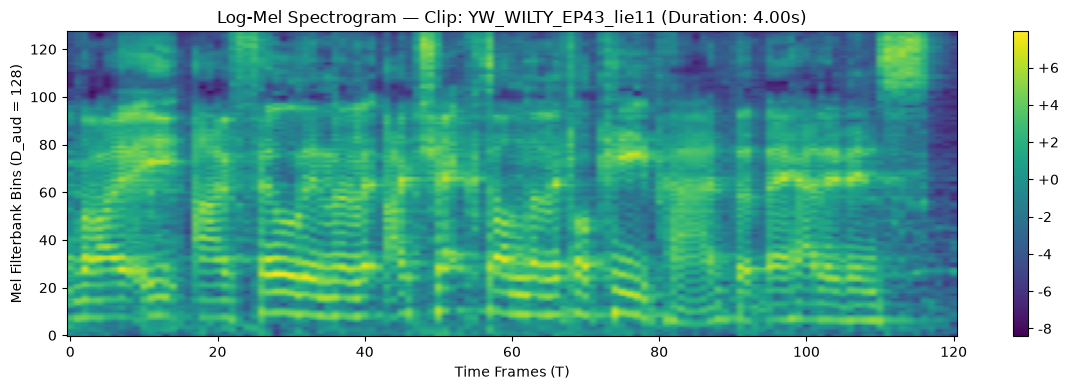

Extracted feature tensor shape: torch.Size([1, 128, 121])
Target format validation -> Expected feature dimensions match D_aud=128.


In [17]:
import torch
import torchaudio.transforms as T
import soundfile as sf
import matplotlib.pyplot as plt

# ==========================================
# Explicit Configuration Parameters
# ==========================================
SAMPLE_RATE = 16000  # Default target sample rate (adjust if needed, e.g., 22050)
N_FFT = 1024
HOP_LENGTH = 533     # Adjust hop length as needed for your time resolution
N_MELS = 128         # Target feature dimension D_aud = 128

print(f"Using direct parameters -> Sample Rate: {SAMPLE_RATE} Hz, N_Mels: {N_MELS}, Hop Length: {HOP_LENGTH}")

# 1. Pick a random clean training clip from audio_eda_df
sample_row = audio_eda_df.sample(n=1, random_state=42).iloc[0]
wav_path = PROJECT_ROOT / sample_row['audio_path']

# 2. Read audio using soundfile
y, sr = sf.read(str(wav_path))

# Resample or handle sample rate conversion if `sr` != `SAMPLE_RATE` is required, 
# or ensure `y` matches the expected SAMPLE_RATE.
waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0)  # Shape: (1, time)

# 3. Define Log-Mel Spectrogram transform using direct specifications
mel_transform = T.MelSpectrogram(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,  
    n_mels=N_MELS            # D_aud = 128
)

mel_spec = mel_transform(waveform)
log_mel_spec = torch.log(mel_spec + 1e-9) # Stabilize log

# 4. Plot the Log-Mel Spectrogram
plt.figure(figsize=(12, 4))
plt.imshow(log_mel_spec[0].numpy(), origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(format='%+2.0f')
plt.title(f"Log-Mel Spectrogram — Clip: {sample_row['clip_id']} (Duration: {sample_row['duration_sec']:.2f}s)")
plt.xlabel("Time Frames (T)")
plt.ylabel(f"Mel Filterbank Bins (D_aud = {N_MELS})")
plt.tight_layout()
plt.show()

print(f"Extracted feature tensor shape: {log_mel_spec.shape}")
print(f"Target format validation -> Expected feature dimensions match D_aud={N_MELS}.")

## Lie vs Truth

This function extracts pitch ($F_0$), voice quality metrics (Jitter, Shimmer, HNR), and spectral features from each audio file.

In [18]:
import parselmouth
from parselmouth.praat import call
import librosa
import numpy as np
import pandas as pd

def extract_deception_features(audio_path):
    """
    Extracts pitch, voice quality, and spectral features from an audio file.
    """
    try:
        # Load sound with Parselmouth
        sound = parselmouth.Sound(audio_path)
        
        # 1. Pitch & Prosody (F0)
        pitch = sound.to_pitch()
        pitch_values = pitch.selected_array['frequency']
        pitch_values = pitch_values[pitch_values > 0] # Filter out unvoiced frames
        
        if len(pitch_values) > 0:
            f0_mean = np.mean(pitch_values)
            f0_std = np.std(pitch_values)
            f0_range = np.max(pitch_values) - np.min(pitch_values)
        else:
            f0_mean, f0_std, f0_range = 0, 0, 0

        # 2. Voice Quality (Perturbation & HNR via Praat)
        point_process = call(sound, "To PointProcess (periodic, cc)", 75, 300)
        jitter = call(point_process, "Get jitter (local)", 0, 0, 0.0001, 0.02, 1.3)
        shimmer = call([sound, point_process], "Get shimmer (local)", 0, 0, 0.0001, 0.02, 1.3, 1.6)
        
        harmonicity = sound.to_harmonicity_cc()
        hnr = call(harmonicity, "Get mean", 0.0, 0.0)
        
        # Handle potential NaN values from Praat
        jitter = 0.0 if np.isnan(jitter) else jitter
        shimmer = 0.0 if np.isnan(shimmer) else shimmer
        hnr = 0.0 if np.isnan(hnr) else hnr

        # 3. Spectral Features (using Librosa)
        y, sr = librosa.load(audio_path, sr=None)
        spectral_centroid = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
        spectral_flatness = np.mean(librosa.feature.spectral_flatness(y=y))

        return {
            'f0_mean': f0_mean,
            'f0_std': f0_std,
            'f0_range': f0_range,
            'jitter': jitter,
            'shimmer': shimmer,
            'hnr': hnr,
            'spectral_centroid': spectral_centroid,
            'spectral_flatness': spectral_flatness
        }
    except Exception as e:
        print(f"Error processing {audio_path}: {e}")
        return None

- The training set has 565 lie clips (55.7%) and 449 truth clips (44.3%), a mild imbalance of about 1.26 : 1.


In [19]:
# Automatically derive the 'label' column from clip_id
audio_eda_df['label'] = audio_eda_df['clip_id'].apply(
    lambda x: 'Lie' if 'lie' in str(x).lower() else ('Truth' if 'truth' or 'true' in str(x).lower() else 'Unknown')
)

# Verify the label distribution
print(audio_eda_df['label'].value_counts())

label
Lie      565
Truth    449
Name: count, dtype: int64


In [20]:
import os
import pandas as pd

feature_records = []

for idx, row in audio_eda_df.iterrows():
    
    filename = os.path.basename(row['audio_path'])
    audio_path = os.path.join('..','data', 'processed', 'audio_train', filename)
    label = row['label']
    
    feats = extract_deception_features(audio_path)
    if feats:
        feats['label'] = label
        feats['clip_id'] = row['clip_id']
        feature_records.append(feats)

# Convert to DataFrame
df_features = pd.DataFrame(feature_records)

# View mean values grouped by Lie vs. Truth
print(df_features.groupby('label').mean(numeric_only=True))

          f0_mean     f0_std    f0_range    jitter   shimmer       hnr  \
label                                                                    
Lie    164.624926  60.110750  366.458606  0.024408  0.126651  7.194119   
Truth  170.893532  60.950299  361.803971  0.023900  0.124276  7.714718   

       spectral_centroid  spectral_flatness  
label                                        
Lie          1963.547359           0.053052  
Truth        1951.255351           0.050595  


- Lie and truth distributions overlap almost completely for all six plotted features. Medians and shapes are nearly identical.
- The largest gap is in pitch mean: lie clips average about 6 Hz lower (roughly 4%). HNR is about 0.5 dB lower for lies. Both gaps are small compared with the spread within each class.
- Pitch variability, jitter, shimmer and spectral centroid show no visible difference.
- *Voice-quality caveat:* the jitter (about 2.4%) and shimmer (about 12.6%) values are far above normal speech values, and HNR (about 7 dB) is low. These features were measured on broadcast audio with background noise and overlapping sounds, so they mostly reflect recording quality, not the speaker's voice.
- *Pitch-range caveat:* the F0 range (about 365 Hz) is probably inflated by pitch-tracking errors (octave jumps).


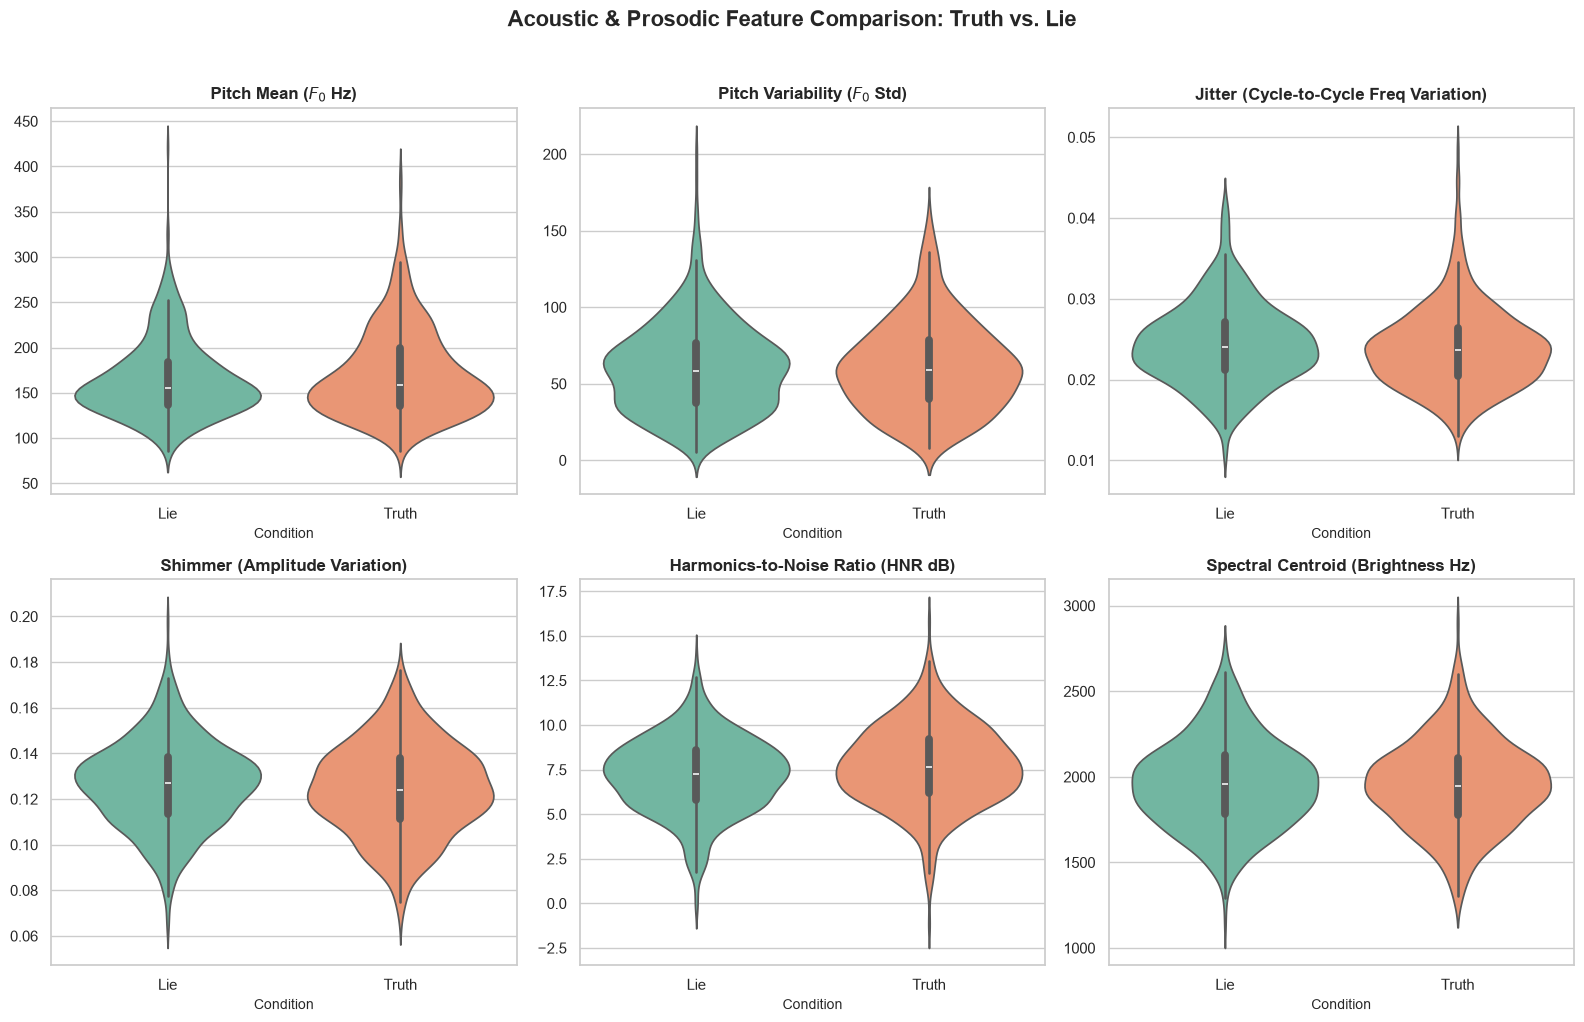

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_lie_vs_truth_comparisons(df):
    features_to_plot = [
        ('f0_mean', 'Pitch Mean ($F_0$ Hz)'),
        ('f0_std', 'Pitch Variability ($F_0$ Std)'),
        ('jitter', 'Jitter (Cycle-to-Cycle Freq Variation)'),
        ('shimmer', 'Shimmer (Amplitude Variation)'),
        ('hnr', 'Harmonics-to-Noise Ratio (HNR dB)'),
        ('spectral_centroid', 'Spectral Centroid (Brightness Hz)')
    ]
    
    plt.figure(figsize=(16, 10))
    sns.set_theme(style="whitegrid")
    
    for i, (feat, title) in enumerate(features_to_plot, 1):
        plt.subplot(2, 3, i)
        sns.violinplot(
            x="label",
            y=feat,
            hue="label",  # 1. Assign hue to the same column as x
            data=df_features,
            palette="Set2",
            legend=False,  # 2. Hide the redundant color legend
        )
        plt.title(title, fontsize=12, fontweight='bold')
        plt.xlabel('Condition', fontsize=10)
        plt.ylabel('', fontsize=10)
        
    plt.suptitle('Acoustic & Prosodic Feature Comparison: Truth vs. Lie', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Generate the plots
plot_lie_vs_truth_comparisons(df_features)

## Removing noise 

In [23]:
import numpy as np
import soundfile as sf
import librosa
import noisereduce as nr

DENOISED_DIR = PROJECT_ROOT / "data" / "processed" / "audio_train_denoised"
DENOISED_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR = PROJECT_ROOT / "data" / "processed" / "audio_train"
SR = 16000


def noise_profile(y, sr=SR, frame_ms=25, quietest=0.25):
    """Concatenate the quietest 25% of non-overlapping frames: an estimate of the clip's own background noise."""
    n = int(sr * frame_ms / 1000)
    m = len(y) // n
    if m < 8:
        return None
    frames = y[: m * n].reshape(m, n)
    energy = (frames ** 2).mean(axis=1)
    quiet = frames[np.argsort(energy)[: max(2, int(m * quietest))]].ravel()
    return quiet if len(quiet) >= 2048 else None      # need at least a couple of FFT windows


def denoise(y, sr=SR):
    prof = noise_profile(y, sr)
    if prof is not None:       # stationary gating against this clip's own noise profile
        out = nr.reduce_noise(y=y, sr=sr, y_noise=prof, stationary=True, prop_decrease=0.9)
    else:                      # very short clip: fall back to the non-stationary estimator
        out = nr.reduce_noise(y=y, sr=sr, stationary=False, prop_decrease=0.9)
    return np.clip(out, -1.0, 1.0).astype(np.float32)


def noise_floor_db(y):
    """10th percentile of frame RMS, in dBFS: a simple, comparable measure of the background level."""
    rms = librosa.feature.rms(y=y)[0]
    return 20 * np.log10(np.percentile(rms, 10) + 1e-9)


# Same treatment for every clip, lie or truth. Never denoise only one class.
records = []
for row in audio_eda_df.itertuples():
    src = RAW_DIR / f"{row.clip_id}.wav"
    dst = DENOISED_DIR / f"{row.clip_id}.wav"
    if not src.exists():
        continue
    y, sr = sf.read(str(src), dtype="float32")
    assert sr == SR, f"{row.clip_id}: expected {SR} Hz, got {sr}"
    y_dn = denoise(y)
    sf.write(str(dst), y_dn, SR, subtype="PCM_16")
    records.append({"clip_id": row.clip_id, "floor_raw_db": noise_floor_db(y), "floor_dn_db": noise_floor_db(y_dn)})

dn_check = pd.DataFrame(records)
dn_check["reduction_db"] = dn_check["floor_raw_db"] - dn_check["floor_dn_db"]
print(f"Denoised {len(dn_check)} clips -> {DENOISED_DIR}")
print(f"Noise floor: {dn_check['floor_raw_db'].mean():.1f} dBFS -> {dn_check['floor_dn_db'].mean():.1f} dBFS "
      f"(mean reduction {dn_check['reduction_db'].mean():.1f} dB, median {dn_check['reduction_db'].median():.1f} dB)")
print("Reduction by label (should be similar; if not, the denoiser is treating the classes differently):")
print(dn_check.merge(audio_eda_df[["clip_id", "label"]], on="clip_id").groupby("label")["reduction_db"].describe().round(2))

Denoised 1014 clips -> ..\data\processed\audio_train_denoised
Noise floor: -39.7 dBFS -> -50.2 dBFS (mean reduction 10.6 dB, median 9.8 dB)
Reduction by label (should be similar; if not, the denoiser is treating the classes differently):
       count   mean   std   min   25%    50%    75%    max
label                                                     
Lie    565.0  10.32  3.87  3.42  7.26   9.66  12.74  20.53
Truth  449.0  10.91  4.02  2.97  7.60  10.14  13.68  21.14


## Extracting the same features with de-noised data

In [24]:
import parselmouth
from parselmouth.praat import call


def extract_features(audio_path):
    """Pitch, voice-quality and spectral features. Missing values are NaN (not 0) so they don't distort statistics."""
    try:
        sound = parselmouth.Sound(str(audio_path))
        duration = sound.get_total_duration()

        # Pitch: 75-400 Hz search range cuts octave-jump errors (the default ceiling is 600 Hz)
        pitch = sound.to_pitch(pitch_floor=75, pitch_ceiling=400)
        f0_all = pitch.selected_array["frequency"]
        f0 = f0_all[f0_all > 0]
        if len(f0) >= 10:
            st = 12 * np.log2(f0 / np.median(f0))               # semitones relative to the speaker's median
            f0_mean, f0_std_st = f0.mean(), st.std()
            f0_range_st = np.percentile(st, 95) - np.percentile(st, 5)   # robust range
        else:
            f0_mean = f0_std_st = f0_range_st = np.nan
        voiced_ratio = len(f0) / max(len(f0_all), 1)

        # Voice quality
        jitter = shimmer = hnr = np.nan
        if len(f0) >= 10:
            pp = call(sound, "To PointProcess (periodic, cc)", 75, 400)
            jitter = call(pp, "Get jitter (local)", 0, 0, 0.0001, 0.02, 1.3)
            shimmer = call([sound, pp], "Get shimmer (local)", 0, 0, 0.0001, 0.02, 1.3, 1.6)
        hnr = call(sound.to_harmonicity_cc(), "Get mean", 0.0, 0.0)

        # Spectral
        y, sr = librosa.load(str(audio_path), sr=None)
        centroid = float(np.mean(librosa.feature.spectral_centroid(y=y, sr=sr)))
        flatness = float(np.mean(librosa.feature.spectral_flatness(y=y)))

        out = {"f0_mean": f0_mean, "f0_std_st": f0_std_st, "f0_range_st": f0_range_st, "voiced_ratio": voiced_ratio,
               "jitter": jitter, "shimmer": shimmer, "hnr": hnr,
               "spectral_centroid": centroid, "spectral_flatness": flatness, "duration_s": duration}
        return {k: (np.nan if (v is None or (isinstance(v, float) and np.isnan(v))) else float(v)) for k, v in out.items()}
    except Exception as e:
        print(f"Error processing {audio_path}: {e}")
        return None


def extract_all(audio_dir):
    recs = []
    for row in audio_eda_df.itertuples():
        feats = extract_features(audio_dir / f"{row.clip_id}.wav")
        if feats:
            recs.append({"clip_id": row.clip_id, "label": row.label, **feats})
    return pd.DataFrame(recs)


# identical extraction on both versions, so the only difference is the denoising
feat_raw = extract_all(RAW_DIR)
feat_dn = extract_all(DENOISED_DIR)
common = sorted(set(feat_raw["clip_id"]) & set(feat_dn["clip_id"]))
feat_raw = feat_raw[feat_raw["clip_id"].isin(common)].reset_index(drop=True)
feat_dn = feat_dn[feat_dn["clip_id"].isin(common)].reset_index(drop=True)
print(f"{len(common)} clips with features in both versions")

print("\nClass means, raw vs denoised:")
print(pd.concat({"raw": feat_raw.groupby("label").mean(numeric_only=True),
                 "denoised": feat_dn.groupby("label").mean(numeric_only=True)}).round(4).T)

1014 clips with features in both versions

Class means, raw vs denoised:
                         raw              denoised           
label                    Lie      Truth        Lie      Truth
f0_mean             155.2239   161.3080   157.4807   163.4202
f0_std_st             3.6422     3.8324     3.7909     3.9312
f0_range_st          11.5466    12.3000    11.7959    12.5236
voiced_ratio          0.5825     0.5886     0.5469     0.5515
jitter                0.0243     0.0237     0.0235     0.0229
shimmer               0.1269     0.1243     0.1317     0.1288
hnr                   7.1941     7.7147     7.5013     7.9830
spectral_centroid  1963.5474  1951.2554  1926.2763  1911.9492
spectral_flatness     0.0531     0.0506     0.0328     0.0322
duration_s            5.3027     5.1982     5.3027     5.1982


AUC = P(lie > truth). q-values: permutation test (labels shuffled within episode) + Benjamini-Hochberg.


AUC (0.5 = no difference)                    \
                               raw / pooled denoised / pooled   
feature                                                         
f0_mean                               0.471             0.471   
f0_std_st                             0.447             0.462   
f0_range_st                           0.441             0.442   
voiced_ratio                          0.483             0.484   
jitter                                0.536             0.530   
shimmer                               0.538             0.547   
hnr                                   0.436             0.441   
spectral_centroid                     0.510             0.516   
spectral_flatness                     0.527             0.514   
duration_s                            0.497             0.497   

                                                                  FDR q-value  \
                  raw / within-episode denoised / within-episode raw / pooled   
feature                                                                         
f0_mean                          0.445                     0.442        0.164   
f0_std_st                        0.445                     0.453        0.007   
f0_range_st                      0.440                     0.436        0.007   
voiced_ratio                     0.487                     0.491        0.438   
jitter                           0.546                     0.533        0.072   
shimmer                          0.529                     0.540        0.086   
hnr                              0.452                     0.461        0.007   
spectral_centroid                0.500                     0.506        0.678   
spectral_flatness                0.524                     0.510        0.221   
duration_s                       0.504                     0.504        0.891   

                                                          \
                  denoised / pooled raw / within-episode   
feature                                                    
f0_mean                       0.185                0.008   
f0_std_st                     0.061                0.008   
f0_range_st                   0.020                0.005   
voiced_ratio                  0.479                0.588   
jitter                        0.126                0.038   
shimmer                       0.030                0.164   
hnr                           0.025                0.014   
spectral_centroid             0.479                0.993   
spectral_flatness             0.479                0.227   
duration_s                    0.891                0.906   

                                             
                  denoised / within-episode  
feature                                      
f0_mean                               0.007  
f0_std_st                             0.030  
f0_range_st                           0.007  
voiced_ratio                          0.785  
jitter                                0.092  
shimmer                               0.035  
hnr                                   0.035  
spectral_centroid                     0.815  
spectral_flatness                     0.785  
duration_s                            0.815

Lie-vs-truth from these features, episode-grouped 5-fold CV (raw): AUC = 0.541 +/- 0.049
Lie-vs-truth from these features, episode-grouped 5-fold CV (denoised): AUC = 0.534 +/- 0.046


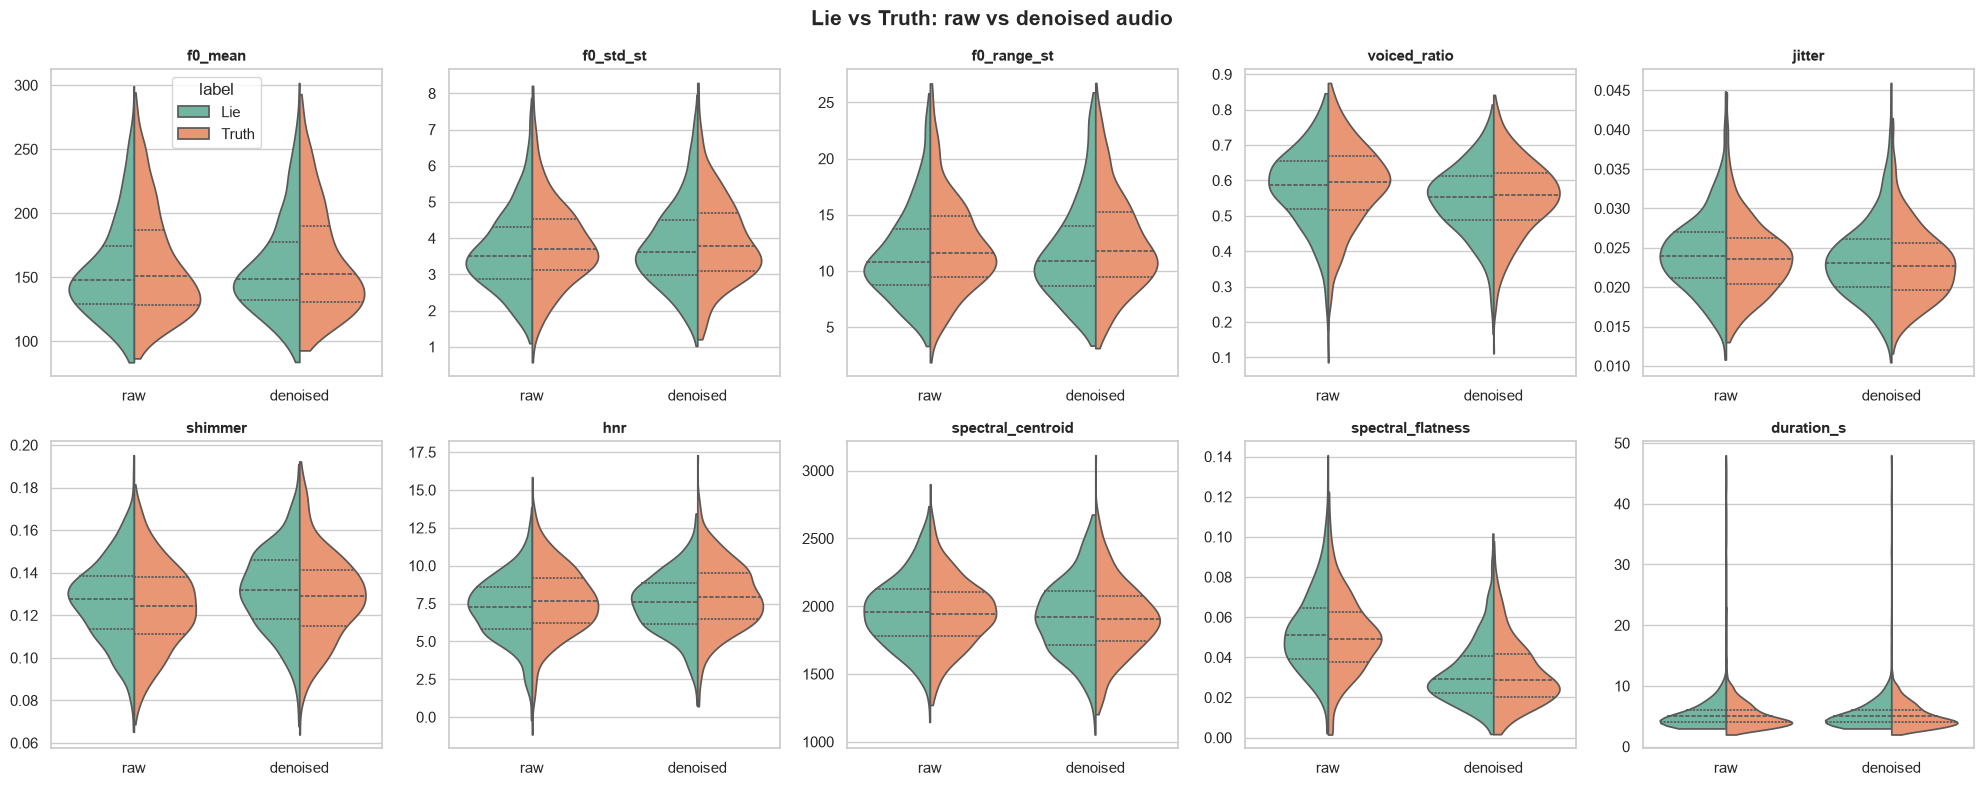

In [25]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import rankdata
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = ["f0_mean", "f0_std_st", "f0_range_st", "voiced_ratio",
            "jitter", "shimmer", "hnr", "spectral_centroid", "spectral_flatness", "duration_s"]
N_PERM, SEED = 2000, 42


def episode_of(clip_id):
    m = re.match(r"(?i)^([A-Za-z]+)_WILTY_(EP\d+)_", str(clip_id).replace(" ", ""))
    return f"{m.group(1).upper()}_{m.group(2).upper()}" if m else str(clip_id)


def prepare(feats):
    d = feats.copy()
    d["episode"] = d["clip_id"].map(episode_of)
    d["y"] = (d["label"] == "Lie").astype(int)
    d[FEATURES] = d[FEATURES].replace([np.inf, -np.inf], np.nan)
    # remove each episode's baseline (median) so we compare lie vs truth *within* the same recording conditions
    for f in FEATURES:
        d[f + "_n"] = d[f] - d.groupby("episode")[f].transform("median")
    return d


def auc_from_ranks(x, y):
    """P(lie > truth) via the Mann-Whitney identity; NaNs must be removed beforehand."""
    n1, n0 = y.sum(), (1 - y).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(x)
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def bh_fdr(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    q = np.empty_like(p)
    scaled = p[order] * len(p) / np.arange(1, len(p) + 1)
    q[order] = np.minimum.accumulate(scaled[::-1])[::-1].clip(max=1)
    return q


def auc_table(d, suffix=""):
    """AUC per feature + permutation p-value, shuffling labels *within episodes* (respects clustering)."""
    rng = np.random.default_rng(SEED)
    y = d["y"].to_numpy()
    groups = [np.asarray(idx) for idx in d.groupby("episode").indices.values()]   # positional indices per episode
    perms = np.empty((N_PERM, len(y)), dtype=y.dtype)
    for k in range(N_PERM):
        yp = y.copy()
        for idx in groups:
            yp[idx] = rng.permutation(y[idx])
        perms[k] = yp
    rows = []
    for f in FEATURES:
        x = d[f + suffix].to_numpy(float)
        ok = ~np.isnan(x)
        auc = auc_from_ranks(x[ok], y[ok])
        null = np.array([auc_from_ranks(x[ok], perms[k][ok]) for k in range(N_PERM)])
        p = (1 + (np.abs(null - 0.5) >= abs(auc - 0.5)).sum()) / (N_PERM + 1)
        rows.append({"feature": f, "auc": auc, "p": p, "n": int(ok.sum())})
    out = pd.DataFrame(rows)
    out["q"] = bh_fdr(out["p"])
    return out.set_index("feature")


def grouped_cv_auc(d, repeats=5):
    X, y, g = d[FEATURES], d["y"].to_numpy(), d["episode"].to_numpy()
    scores = []
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + r)
        for tr, te in cv.split(X, y, g):
            m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
            m.fit(X.iloc[tr], y[tr])
            scores.append(roc_auc_score(y[te], m.predict_proba(X.iloc[te])[:, 1]))
    return np.mean(scores), np.std(scores)


def compare(feat_raw, feat_dn):
    raw, dn = prepare(feat_raw), prepare(feat_dn)
    tabs = {
        "raw / pooled": auc_table(raw),
        "denoised / pooled": auc_table(dn),
        "raw / within-episode": auc_table(raw, "_n"),
        "denoised / within-episode": auc_table(dn, "_n"),
    }
    auc = pd.concat({k: v["auc"] for k, v in tabs.items()}, axis=1)
    q = pd.concat({k: v["q"] for k, v in tabs.items()}, axis=1)
    summary = pd.concat({"AUC (0.5 = no difference)": auc, "FDR q-value": q}, axis=1)
    print("AUC = P(lie > truth). q-values: permutation test (labels shuffled within episode) + Benjamini-Hochberg.")
    display(summary.round(3))

    for name, d in (("raw", raw), ("denoised", dn)):
        m, s = grouped_cv_auc(d)
        print(f"Lie-vs-truth from these features, episode-grouped 5-fold CV ({name}): AUC = {m:.3f} +/- {s:.3f}")

    # violin plots: lie vs truth, raw next to denoised, for each feature
    long = pd.concat([raw.assign(version="raw"), dn.assign(version="denoised")], ignore_index=True)
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    for ax, f in zip(axes.ravel(), FEATURES):
        sns.violinplot(data=long, x="version", y=f, hue="label", split=True, inner="quart",
                       palette="Set2", order=["raw", "denoised"], ax=ax, cut=0)
        ax.set_title(f, fontsize=11, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("")
        if ax is not axes.ravel()[0]:
            ax.get_legend().remove()
    plt.suptitle("Lie vs Truth: raw vs denoised audio", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()
    return summary


summary = compare(feat_raw, feat_dn)

## Timing features Comparisons

- The energy-based VAD found no usable speech/background contrast in 20 of 1,014 clips (2%). Those clips have no timing features, which leaves 994 for analysis. Pause-length features have 893 clips because 101 clips contain no pause.
- The spot-check plots show the detected speech segments (green) covering the spoken parts, and the syllable markers (red) landing on energy peaks. The segmentation is good enough for clip-level statistics.
- Syllable counts are estimates and can miss weak syllables inside long bursts, so treat the speech-rate features as relative measures.
- Clips are cut tightly around the speech: the median leading silence is 0.008 s and the median trailing silence is 0.013 s. Response delay before speaking therefore cannot be measured, and `leading_silence_s` carries no information in this dataset.
- The 0.15 s minimum pause set in the code is why pause-length violins end at about 0.15 s.

### Class medians
- Lie and truth clips are almost identical on pause behaviour: both medians are 2 pauses and 3 speech segments, with a mean pause of about 0.33 s and a pause ratio of about 0.14.
- The only visible gap is speaking speed: 3.67 syllables/s for lies vs 3.43 for truths overall, and 4.51 vs 4.28 during actual speech.


1014 clips | VAD backend: energy | clips with no usable speech/background contrast: 20

Class medians:
label                 Lie  Truth
speech_ratio        0.836  0.820
leading_silence_s   0.008  0.008
trailing_silence_s  0.013  0.013
n_pauses            2.000  2.000
pause_rate          0.376  0.402
mean_pause_s        0.330  0.338
max_pause_s         0.430  0.430
pause_ratio         0.137  0.139
n_segments          3.000  3.000
mean_burst_s        1.390  1.375
longest_burst_s     2.330  2.290
speech_rate         3.667  3.429
articulation_rate   4.505  4.279
syll_interval_cv    0.370  0.370
energy_std_db       6.571  6.849


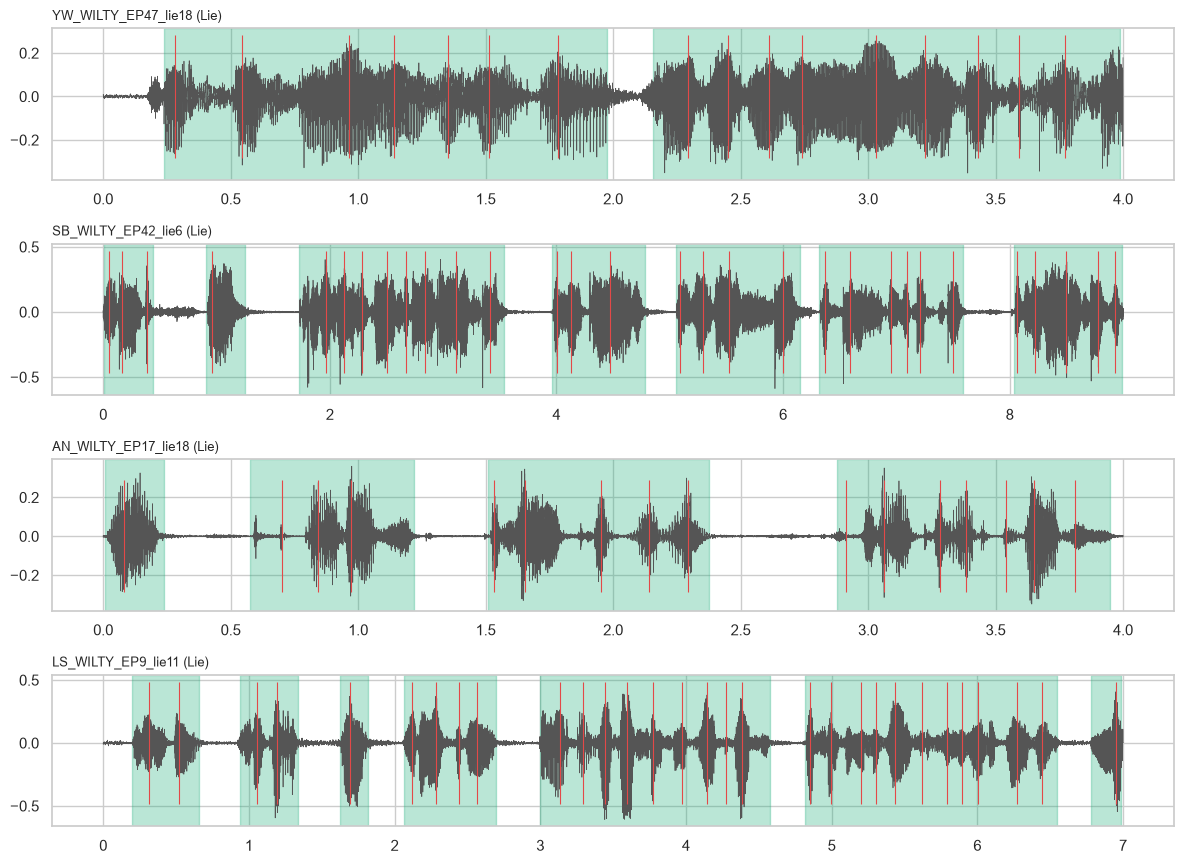

In [26]:
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.signal import butter, sosfiltfilt, find_peaks

AUDIO_DIR = RAW_DIR          # denoising made no difference, so use the raw audio
SR = 16000
FRAME, HOP = 0.025, 0.010    # 25 ms frames, 10 ms hop
MIN_PAUSE_S = 0.15           # silences shorter than this are not counted as pauses
MIN_SPEECH_S = 0.10          # speech bursts shorter than this are dropped
VAD_BACKEND = "energy"       # "energy" (no extra install) or "silero" (pip install silero-vad; usually better)

TIMING_FEATURES = [
    "speech_ratio", "leading_silence_s", "trailing_silence_s",
    "n_pauses", "pause_rate", "mean_pause_s", "max_pause_s", "pause_ratio",
    "n_segments", "mean_burst_s", "longest_burst_s",
    "speech_rate", "articulation_rate", "syll_interval_cv", "energy_std_db",
]


def frame_db(y):
    n, h = int(FRAME * SR), int(HOP * SR)
    if len(y) < n:
        y = np.pad(y, (0, n - len(y)))
    c = np.concatenate(([0.0], np.cumsum(y.astype(np.float64) ** 2)))
    s = np.arange(0, len(y) - n + 1, h)
    return 10 * np.log10((c[s + n] - c[s]) / n + 1e-12)


def mask_to_segments(mask):
    d = np.diff(np.concatenate(([0], mask.astype(np.int8), [0])))
    starts, ends = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    off = (FRAME - HOP) / 2                       # centre each frame on its hop
    return [(s * HOP + off, e * HOP + off) for s, e in zip(starts, ends)]


def energy_segments(y, min_contrast_db=10.0, thr_frac=0.4):
    """Adaptive per-clip threshold between the 10th and 90th percentile frame energy.
    Returns None when speech and background are not separable (flat energy)."""
    db = frame_db(y)
    if db.size < 20:
        return None
    lo, hi = np.percentile(db, [10, 90])
    if hi - lo < min_contrast_db:
        return None
    mask = db > lo + thr_frac * (hi - lo)
    mask = ndimage.median_filter(mask.astype(np.uint8), size=3).astype(bool)
    return mask_to_segments(mask)


_silero_model = None
def silero_segments(y):
    global _silero_model
    import torch
    from silero_vad import load_silero_vad, get_speech_timestamps
    if _silero_model is None:
        _silero_model = load_silero_vad()
    ts = get_speech_timestamps(torch.from_numpy(y), _silero_model, sampling_rate=SR, return_seconds=True)
    return [(t["start"], t["end"]) for t in ts]


def clean_segments(segs, dur):
    """Merge gaps shorter than MIN_PAUSE_S (they are not pauses), then drop bursts shorter than MIN_SPEECH_S."""
    merged = []
    for s, e in segs:
        s, e = max(0.0, s), min(dur, e)
        if e <= s:
            continue
        if merged and s - merged[-1][1] < MIN_PAUSE_S:
            merged[-1][1] = e
        else:
            merged.append([s, e])
    return [(s, e) for s, e in merged if e - s >= MIN_SPEECH_S]


def syllable_nuclei(y, segs):
    """Syllable-like energy peaks (>= 3 dB prominence, >= 100 ms apart) in the 300-3000 Hz band, inside speech."""
    if len(y) < 200 or not segs:
        return np.array([])
    sos = butter(4, [300, 3000], btype="band", fs=SR, output="sos")
    db = ndimage.uniform_filter1d(frame_db(sosfiltfilt(sos, y)), 3)
    peaks, _ = find_peaks(db, prominence=3.0, distance=max(1, int(0.10 / HOP)))
    t = peaks * HOP + FRAME / 2
    inside = np.zeros(len(t), bool)
    for s, e in segs:
        inside |= (t >= s) & (t <= e)
    return t[inside]


def analyze_clip(y):
    dur = len(y) / SR
    out = dict.fromkeys(TIMING_FEATURES, np.nan)
    raw = silero_segments(y) if VAD_BACKEND == "silero" else energy_segments(y)
    out["vad_ok"] = raw is not None
    if raw is None:
        return out, [], np.array([])
    segs = clean_segments(raw, dur)
    if not segs:
        out["speech_ratio"] = 0.0
        return out, segs, np.array([])

    speech_time = sum(e - s for s, e in segs)
    first, last = segs[0][0], segs[-1][1]
    span = last - first
    gaps = [segs[i + 1][0] - segs[i][1] for i in range(len(segs) - 1)]   # all >= MIN_PAUSE_S after merging
    nuclei = syllable_nuclei(y, segs)

    out.update(
        speech_ratio=speech_time / dur,
        leading_silence_s=first,                      # delay before the speaker starts
        trailing_silence_s=dur - last,
        n_pauses=float(len(gaps)),
        pause_rate=len(gaps) / span if span > 0 else np.nan,
        mean_pause_s=float(np.mean(gaps)) if gaps else np.nan,
        max_pause_s=float(np.max(gaps)) if gaps else np.nan,
        pause_ratio=float(sum(gaps)) / span if span > 0 else np.nan,
        n_segments=float(len(segs)),
        mean_burst_s=speech_time / len(segs),
        longest_burst_s=max(e - s for s, e in segs),
        speech_rate=len(nuclei) / dur,                # syllables per second, including pauses
        articulation_rate=len(nuclei) / speech_time,  # syllables per second of actual speech
    )
    if len(nuclei) >= 4:
        iv = np.diff(nuclei)
        iv = iv[iv < 0.5]                             # ignore intervals that span a pause
        if len(iv) >= 3:
            out["syll_interval_cv"] = float(iv.std() / iv.mean())   # rhythm irregularity
    db = frame_db(y)
    t = np.arange(len(db)) * HOP + FRAME / 2
    in_speech = np.zeros(len(db), bool)
    for s, e in segs:
        in_speech |= (t >= s) & (t <= e)
    if in_speech.sum() >= 10:
        out["energy_std_db"] = float(db[in_speech].std())
    return out, segs, nuclei


def read_mono(path):
    y, sr = sf.read(str(path), dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    assert sr == SR, f"{path}: expected {SR} Hz, got {sr}"
    return y


records = []
for row in audio_eda_df.itertuples():
    p = AUDIO_DIR / f"{row.clip_id}.wav"
    if not p.exists():
        continue
    feats, _, _ = analyze_clip(read_mono(p))
    records.append({"clip_id": row.clip_id, "label": row.label, **feats})

feat_timing = pd.DataFrame(records)
print(f"{len(feat_timing)} clips | VAD backend: {VAD_BACKEND} | "
      f"clips with no usable speech/background contrast: {(~feat_timing['vad_ok']).sum()}")
print("\nClass medians:")
print(feat_timing.groupby("label")[TIMING_FEATURES].median().T.round(3))


def plot_vad_examples(n=4, seed=0):
    """Sanity check: do the detected speech segments (green) and syllable peaks (red) match what you hear?"""
    pick = feat_timing[feat_timing["vad_ok"]].sample(n, random_state=seed)
    fig, axes = plt.subplots(n, 1, figsize=(12, 2.2 * n), sharex=False)
    for ax, row in zip(np.atleast_1d(axes), pick.itertuples()):
        y = read_mono(AUDIO_DIR / f"{row.clip_id}.wav")
        _, segs, nuclei = analyze_clip(y)
        ax.plot(np.arange(len(y)) / SR, y, lw=0.5, color="#555")
        for s, e in segs:
            ax.axvspan(s, e, color="#1baf7a", alpha=0.3)
        ax.vlines(nuclei, -0.8 * np.abs(y).max(), 0.8 * np.abs(y).max(), color="#e34948", lw=0.8)
        ax.set_title(f"{row.clip_id} ({row.label})", fontsize=9, loc="left")
    plt.tight_layout()
    plt.show()


plot_vad_examples()

### Statistical comparison 
- **Speech rate** (AUC 0.569, q = 0.004) and **articulation rate** (AUC 0.571, q = 0.004) are the only significant timing features. Lies are spoken faster, about 5–7% faster by the medians. The pooled comparison gives the same result (AUC 0.58, q = 0.004), so the effect is not an episode artifact.
- No pause feature differs: number of pauses, pause rate, mean and max pause length, and pause ratio all have AUC between 0.48 and 0.49 and q ≥ 0.57.
- Burst length, speech ratio, rhythm irregularity (`syll_interval_cv`), loudness variability (`energy_std_db`) and trailing silence show no significant difference (q ≥ 0.57).
- Hesitation and pausing, often assumed to mark lying, do not separate the two classes in this dataset. The tendency is slightly toward more speech and faster delivery for lies.


AUC = P(lie > truth); below 0.5 means LOWER for lies. q: within-episode permutation + Benjamini-Hochberg.


,AUC pooled,AUC within-ep,q pooled,q within-ep,n
feature,,,,,
energy_std_db,0.476,0.471,0.385,0.568,994
pause_ratio,0.479,0.481,0.544,0.569,994
trailing_silence_s,0.475,0.483,0.385,0.569,994
n_pauses,0.487,0.487,0.544,0.601,994
n_segments,0.487,0.487,0.544,0.601,994
max_pause_s,0.477,0.487,0.544,0.601,893
mean_pause_s,0.482,0.488,0.544,0.601,893
syll_interval_cv,0.497,0.488,0.865,0.601,992
pause_rate,0.486,0.491,0.544,0.652,994



Episode-grouped 5-fold CV, logistic regression (AUC, 0.5 = chance):
  prosody + voice quality (previous section) 0.541 +/- 0.049
  timing only                                0.534 +/- 0.034
  prosody + timing                           0.556 +/- 0.035


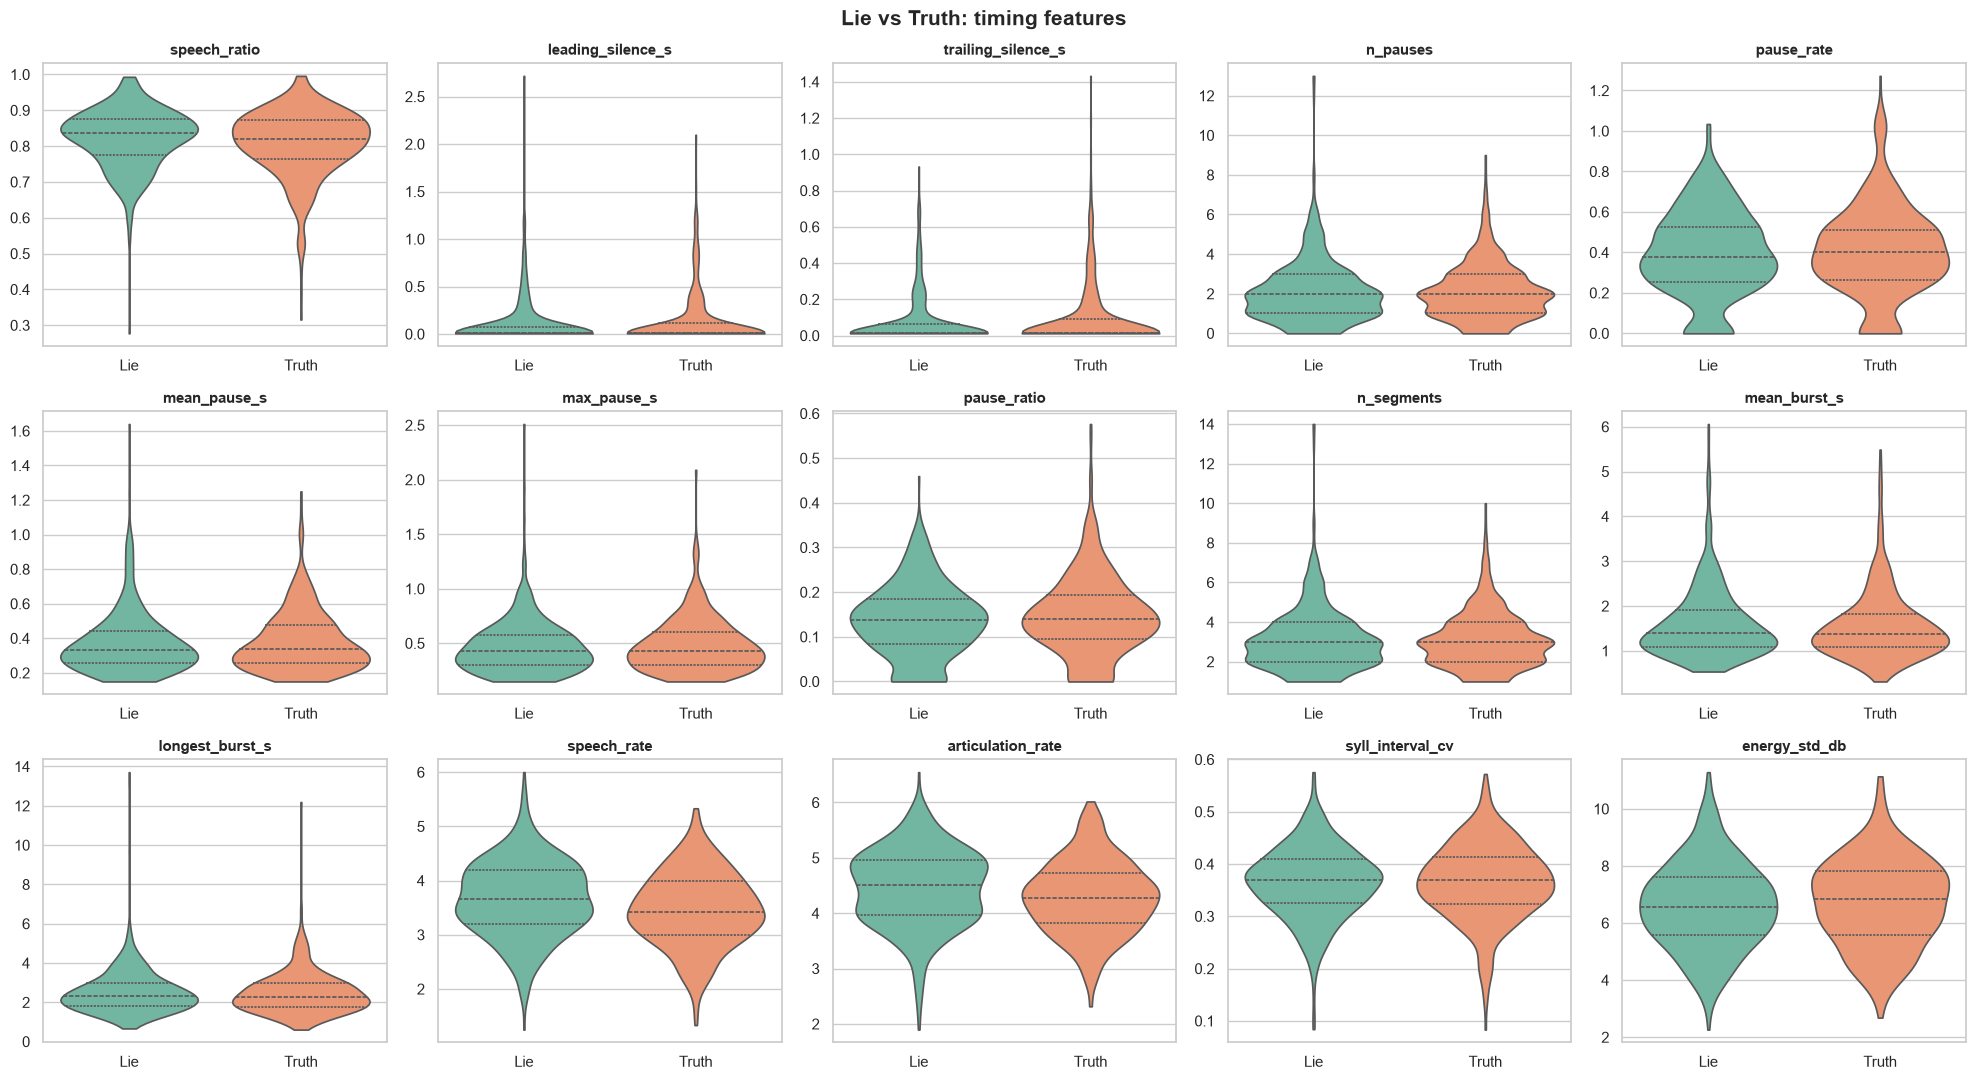

In [27]:
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROSODY_FEATURES = list(FEATURES)     # the 10 features from the previous section (includes duration_s)

# --- per-feature AUC with within-episode permutation test ---
_saved = FEATURES
FEATURES = TIMING_FEATURES            # prepare()/auc_table() read this global
try:
    d_t = prepare(feat_timing)
    pooled, within = auc_table(d_t), auc_table(d_t, "_n")
finally:
    FEATURES = _saved

tab = pd.concat({"AUC pooled": pooled["auc"], "AUC within-ep": within["auc"],
                 "q pooled": pooled["q"], "q within-ep": within["q"], "n": pooled["n"]}, axis=1)
print("AUC = P(lie > truth); below 0.5 means LOWER for lies. q: within-episode permutation + Benjamini-Hochberg.")
display(tab.sort_values("AUC within-ep").round(3))


# --- does timing add anything beyond prosody? episode-grouped CV ---
def cv_auc(df, cols, repeats=5):
    X, y, g = df[cols], df["y"].to_numpy(), df["episode"].to_numpy()
    scores = []
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42 + r)
        for tr, te in cv.split(X, y, g):
            m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
            m.fit(X.iloc[tr], y[tr])
            scores.append(roc_auc_score(y[te], m.predict_proba(X.iloc[te])[:, 1]))
    return np.mean(scores), np.std(scores)

all_df = feat_timing.merge(feat_raw[["clip_id"] + PROSODY_FEATURES], on="clip_id", how="inner")
all_df["episode"] = all_df["clip_id"].map(episode_of)
all_df["y"] = (all_df["label"] == "Lie").astype(int)
all_df = all_df.replace([np.inf, -np.inf], np.nan)

print("\nEpisode-grouped 5-fold CV, logistic regression (AUC, 0.5 = chance):")
for name, cols in {"prosody + voice quality (previous section)": PROSODY_FEATURES,
                   "timing only": TIMING_FEATURES,
                   "prosody + timing": PROSODY_FEATURES + TIMING_FEATURES}.items():
    m, s = cv_auc(all_df, cols)
    print(f"  {name:<42} {m:.3f} +/- {s:.3f}")

# --- distributions ---
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, f in zip(axes.ravel(), TIMING_FEATURES):
    sns.violinplot(data=feat_timing, x="label", y=f, hue="label", palette="Set2", inner="quart",
                   cut=0, order=["Lie", "Truth"], legend=False, ax=ax)
    ax.set_title(f, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.ravel()[len(TIMING_FEATURES):]:
    ax.axis("off")
plt.suptitle("Lie vs Truth: timing features", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Combined model 

| Feature set | AUC |
|---|---|
| Prosody + voice quality | 0.541 ± 0.049 |
| Timing only | 0.534 ± 0.034 |
| Prosody + timing | 0.556 ± 0.035 |

- Adding timing features improves AUC by only about 0.015, which is within the fold-to-fold variation. Each feature set gives only a small edge over chance.
- Together with the previous section, lies show slightly lower pitch, a narrower pitch range, lower HNR and faster speech. Each effect is small, and combined they reach AUC ≈ 0.55.


## eGeMAPS (88 features)

In [34]:
import opensmile

smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,           # 88 functionals: pitch, loudness, formants, spectral, voice quality
    feature_level=opensmile.FeatureLevel.Functionals,
)

recs = []
for row in audio_eda_df.itertuples():
    p = AUDIO_DIR / f"{row.clip_id}.wav"
    if not p.exists():
        continue
    try:
        r = smile.process_file(str(p)).iloc[0]
        recs.append({"clip_id": row.clip_id, "label": row.label, **r.to_dict()})
    except Exception as e:
        print(f"Error processing {row.clip_id}: {e}")

feat_ege = pd.DataFrame(recs)
EGEMAPS_FEATURES = [c for c in feat_ege.columns if c not in ("clip_id", "label")]
print(f"{len(feat_ege)} clips x {len(EGEMAPS_FEATURES)} eGeMAPS features")
print("Features with missing values:", int(feat_ege[EGEMAPS_FEATURES].isna().any().sum()))

1014 clips x 88 eGeMAPS features
Features with missing values: 0


## pitch and loudness contour dynamics

In [30]:
import numpy as np
import pandas as pd
import parselmouth
from scipy.stats import skew

CONTOUR_FEATURES = [
    "f0_slope_st_per_s", "f0_end_minus_start_st", "f0_skew",
    "f0_delta_abs_mean", "f0_jump_rate",
    "int_slope_db_per_s", "int_end_minus_start_db", "int_range_db", "int_delta_abs_mean", "f0_int_corr",
]


def contour_features(t, f0, db):
    """Dynamics of the pitch and loudness contours.
    t: frame times (s), f0: Hz (0 = unvoiced), db: intensity (dB) at the same times. Only voiced frames are used."""
    out = dict.fromkeys(CONTOUR_FEATURES, np.nan)
    voiced = (f0 > 0) & np.isfinite(db)
    if voiced.sum() < 20:
        return out
    dt = float(np.median(np.diff(t)))
    tv, dv = t[voiced], db[voiced]
    st = 12 * np.log2(f0[voiced] / np.median(f0[voiced]))          # semitones relative to the clip's median pitch
    k = max(3, int(0.2 * len(st)))

    out["f0_slope_st_per_s"] = float(np.polyfit(tv, st, 1)[0])      # overall rise / fall
    out["f0_end_minus_start_st"] = float(np.median(st[-k:]) - np.median(st[:k]))   # final intonation vs start
    out["f0_skew"] = float(skew(st))
    out["int_slope_db_per_s"] = float(np.polyfit(tv, dv, 1)[0])
    out["int_end_minus_start_db"] = float(np.median(dv[-k:]) - np.median(dv[:k]))
    out["int_range_db"] = float(np.percentile(dv, 95) - np.percentile(dv, 5))
    out["f0_int_corr"] = float(np.corrcoef(st, dv)[0, 1]) if st.std() > 0 and dv.std() > 0 else np.nan

    adjacent = np.diff(tv) < 1.5 * dt                               # only consecutive voiced frames
    if adjacent.sum() >= 10:
        d_st, d_db = np.diff(st)[adjacent], np.diff(dv)[adjacent]
        out["f0_delta_abs_mean"] = float(np.abs(d_st).mean() / dt)  # semitones per second: how fast pitch moves
        out["f0_jump_rate"] = float((np.abs(d_st) > 2.0).mean())    # abrupt jumps (also catches pitch-tracker errors)
        out["int_delta_abs_mean"] = float(np.abs(d_db).mean() / dt)  # dB per second
    return out


def extract_contour(path):
    try:
        snd = parselmouth.Sound(str(path))
        pitch = snd.to_pitch(pitch_floor=75, pitch_ceiling=400)
        t, f0 = pitch.xs(), pitch.selected_array["frequency"]
        inten = snd.to_intensity(minimum_pitch=75, time_step=float(np.median(np.diff(t))))
        db = np.interp(t, inten.xs(), inten.values[0])               # align intensity to the pitch frames
        return contour_features(t, f0, db)
    except Exception as e:
        print(f"Error processing {path}: {e}")
        return None


recs = []
for row in audio_eda_df.itertuples():
    f = extract_contour(AUDIO_DIR / f"{row.clip_id}.wav")
    if f:
        recs.append({"clip_id": row.clip_id, "label": row.label, **f})
feat_contour = pd.DataFrame(recs)
print(f"{len(feat_contour)} clips | missing values per feature:")
print(feat_contour[CONTOUR_FEATURES].isna().sum().to_string())
print("\nClass medians:")
print(feat_contour.groupby("label")[CONTOUR_FEATURES].median().T.round(3))

1014 clips | missing values per feature:
f0_slope_st_per_s         1
f0_end_minus_start_st     1
f0_skew                   1
f0_delta_abs_mean         1
f0_jump_rate              1
int_slope_db_per_s        1
int_end_minus_start_db    1
int_range_db              1
int_delta_abs_mean        1
f0_int_corr               1

Class medians:
label                       Lie   Truth
f0_slope_st_per_s        -0.643  -0.678
f0_end_minus_start_st    -3.030  -3.128
f0_skew                   0.314   0.277
f0_delta_abs_mean        35.495  34.737
f0_jump_rate              0.015   0.014
int_slope_db_per_s       -0.390  -0.345
int_end_minus_start_db   -1.887  -1.896
int_range_db             16.418  16.867
int_delta_abs_mean      100.119  96.795
f0_int_corr               0.309   0.308


## Contour Dynamics and eGeMAPS: Lie vs Truth 

### Pitch and loudness contour dynamics (10 features)
- No contour-dynamics feature separates lies from truths. The smallest q-value is 0.16 (`int_range_db`, AUC 0.458), and every other feature has AUC between 0.50 and 0.53 and q ≥ 0.63.
- Class medians are almost identical: pitch slope (−0.64 vs −0.68 st/s), final pitch drop (−3.0 vs −3.1 st), jump rate (0.015 vs 0.014).
- Alone, these features reach CV AUC 0.532 ± 0.046, which is not distinguishable from chance. Adding them to prosody + timing lowered CV AUC from 0.556 to 0.542, so they add noise.
- The contour dynamics are dropped. The earlier clip-level pitch statistics (mean and range) carry the useful pitch information.

### eGeMAPS (88 features)
10 of 88 features are significant within-episode (q < 0.05, 10,000 permutations, Benjamini-Hochberg).

| Feature | AUC | q | Lies vs truths |
|---|---|---|---|
| loudnessPeaksPerSec | 0.567 | 0.009 | more loudness peaks per second |
| HNRdBACF_sma3nz_amean | 0.435 | 0.015 | lower harmonics-to-noise ratio |
| VoicedSegmentsPerSec | 0.563 | 0.015 | more voiced segments per second |
| MeanVoicedSegmentLengthSec | 0.438 | 0.015 | shorter voiced segments |
| F0 (semitone) 80th percentile | 0.439 | 0.016 | lower high-pitch range |
| F0 (semitone) mean | 0.443 | 0.018 | lower pitch |
| jitterLocal (std, normalized) | 0.442 | 0.020 | less variable jitter |
| logRelF0-H1-H2 (mean) | 0.447 | 0.028 | lower H1–H2 (more pressed, less breathy phonation) |
| loudness mean falling slope | 0.552 | 0.028 | faster loudness drops |
| F2 frequency (std, normalized) | 0.553 | 0.028 | more variable second formant |

The significant features fall into three groups, matching the earlier sections:
1. **Lower pitch:** the F0 mean and 80th percentile are lower, matching the earlier `f0_mean` and `f0_range_st` results.
2. **Less clear voice:** lower HNR and lower H1–H2, matching the earlier `hnr` result.
3. **Faster, more fragmented speech:** more loudness peaks and voiced segments per second, shorter voiced segments, and more F2 variability. This matches the faster `speech_rate` and `articulation_rate` found earlier.

Three independently computed feature sets point the same way, which makes these results more credible than any single feature.

### Combined classifier (episode-grouped 5-fold CV, logistic regression)

| Feature set | AUC |
|---|---|
| Prosody + timing (25) | 0.556 ± 0.035 |
| Contour dynamics only | 0.532 ± 0.046 |
| Prosody + timing + contour | 0.542 ± 0.032 |
| eGeMAPS only (88) | 0.551 ± 0.034 |
| Everything | 0.528 ± 0.038 |

- Every set stays at AUC 0.53–0.56, within about one standard deviation of each other and only slightly above chance.
- Adding more features does not help and tends to hurt: "everything" is the worst set. A small, selected set is better than a large one.


In [31]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def within_episode_auc(df, cols, n_perm=10_000):
    """AUC per feature after removing each episode's median, with a within-episode permutation test + BH-FDR over `cols`.
    n_perm must grow with the number of features: the smallest p-value is 1/(n_perm+1), and after BH over k features the
    smallest possible q is k/(n_perm+1). With 88 features and 2,000 permutations no q could drop below 0.044."""
    global FEATURES, N_PERM
    saved, saved_n = FEATURES, N_PERM
    FEATURES, N_PERM = list(cols), n_perm     # prepare()/auc_table() read these globals
    try:
        return auc_table(prepare(df), "_n")
    finally:
        FEATURES, N_PERM = saved, saved_n


def cv_auc2(df, cols, C=1.0, repeats=5):
    X, y, g = df[cols], df["y"].to_numpy(), df["episode"].to_numpy()
    scores = []
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42 + r)
        for tr, te in cv.split(X, y, g):
            m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=C, max_iter=2000))
            m.fit(X.iloc[tr], y[tr])
            scores.append(roc_auc_score(y[te], m.predict_proba(X.iloc[te])[:, 1]))
    return np.mean(scores), np.std(scores)


# --- eGeMAPS: 88 features, so expect a few false positives; rely on the q-value, not the AUC alone ---
ege_tab = within_episode_auc(feat_ege, EGEMAPS_FEATURES)
ege_tab["effect"] = (ege_tab["auc"] - 0.5).abs()
print(f"eGeMAPS: {(ege_tab['q'] < 0.05).sum()} of {len(ege_tab)} features with q < 0.05 (within-episode)")
display(ege_tab.sort_values("q").head(15)[["auc", "p", "q", "n"]].round(4))

# --- pitch / loudness contour dynamics ---
con_tab = within_episode_auc(feat_contour, CONTOUR_FEATURES)
print("\nContour dynamics (AUC < 0.5 = lower for lies):")
display(con_tab.sort_values("q")[["auc", "p", "q", "n"]].round(4))

# --- does any of it improve the classifier? episode-grouped CV ---
all_df = (feat_raw[["clip_id", "label"] + PROSODY_FEATURES]
          .merge(feat_timing[["clip_id"] + TIMING_FEATURES], on="clip_id")
          .merge(feat_contour[["clip_id"] + CONTOUR_FEATURES], on="clip_id")
          .merge(feat_ege[["clip_id"] + EGEMAPS_FEATURES], on="clip_id"))
all_df["episode"] = all_df["clip_id"].map(episode_of)
all_df["y"] = (all_df["label"] == "Lie").astype(int)
all_df = all_df.replace([np.inf, -np.inf], np.nan)

sets = {
    "prosody + timing (25 features)": (PROSODY_FEATURES + TIMING_FEATURES, 1.0),
    "contour dynamics only": (CONTOUR_FEATURES, 1.0),
    "prosody + timing + contour": (PROSODY_FEATURES + TIMING_FEATURES + CONTOUR_FEATURES, 1.0),
    "eGeMAPS only (88, C=0.05)": (EGEMAPS_FEATURES, 0.05),
    "everything (C=0.05)": (PROSODY_FEATURES + TIMING_FEATURES + CONTOUR_FEATURES + EGEMAPS_FEATURES, 0.05),
}
print("\nEpisode-grouped 5-fold CV, logistic regression (AUC, 0.5 = chance):")
for name, (cols, C) in sets.items():
    m, s = cv_auc2(all_df, cols, C=C)
    print(f"  {name:<34} {m:.3f} +/- {s:.3f}")

C:\Users\Mustafa\AppData\Local\Temp\ipykernel_21860\2221500556.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d[f + "_n"] = d[f] - d.groupby("episode")[f].transform("median")


eGeMAPS: 10 of 88 features with q < 0.05 (within-episode)


,auc,p,q,n
feature,,,,
loudnessPeaksPerSec,0.5670,0.0001,0.0088,1014
HNRdBACF_sma3nz_amean,0.4353,0.0006,0.0154,1014
VoicedSegmentsPerSec,0.5630,0.0007,0.0154,1014
MeanVoicedSegmentLengthSec,0.4382,0.0007,0.0154,1014
F0semitoneFrom27.5Hz_sma3nz_percentile80.0,0.4386,0.0009,0.0158,1014
F0semitoneFrom27.5Hz_sma3nz_amean,0.4425,0.0012,0.0176,1014
jitterLocal_sma3nz_stddevNorm,0.4422,0.0016,0.0201,1014
logRelF0-H1-H2_sma3nz_amean,0.4467,0.0027,0.0282,1014
loudness_sma3_meanFallingSlope,0.5520,0.0031,0.0282,1014



Contour dynamics (AUC < 0.5 = lower for lies):


,auc,p,q,n
feature,,,,
int_range_db,0.4581,0.0162,0.1620,1013
f0_skew,0.5272,0.1261,0.6304,1013
f0_delta_abs_mean,0.5134,0.4442,0.6831,1013
f0_slope_st_per_s,0.5141,0.4238,0.6831,1013
int_slope_db_per_s,0.5126,0.4782,0.6831,1013
f0_jump_rate,0.5127,0.4715,0.6831,1013
int_delta_abs_mean,0.5165,0.3684,0.6831,1013
f0_end_minus_start_st,0.5066,0.6960,0.7141,1013
int_end_minus_start_db,0.5097,0.5786,0.7141,1013



Episode-grouped 5-fold CV, logistic regression (AUC, 0.5 = chance):
  prosody + timing (25 features)     0.556 +/- 0.035
  contour dynamics only              0.532 +/- 0.046
  prosody + timing + contour         0.542 +/- 0.032
  eGeMAPS only (88, C=0.05)          0.551 +/- 0.034
  everything (C=0.05)                0.528 +/- 0.038


## Final features added (excluding the log-Mel Spectogram `d_aud` )
| # | Feature | Cell | DataFrame | How it's computed | Evidence (within-episode) |
|---|---|---|---|---|---|
| 1 | `f0_mean` | Cell 2, `extract_features` | `feat_raw` | Mean F0 (Hz) over voiced frames, Praat pitch with a 75–400 Hz range | AUC 0.44, q = 0.007 |
| 2 | `f0_range_st` | Cell 2, `extract_features` | `feat_raw` | 95th minus 5th percentile of F0 in semitones, relative to the clip median | AUC 0.44, q = 0.007 |
| 3 | `articulation_rate` | Cell 4, `analyze_clip` | `feat_timing` | Syllable-like energy peaks per second of detected speech | AUC 0.57, q = 0.004 |
| 4 | `HNRdBACF_sma3nz_amean` | Cell 6, opensmile | `feat_ege` | eGeMAPS mean harmonics-to-noise ratio | AUC 0.435, q = 0.015 |
| 5 | `logRelF0-H1-H2_sma3nz_amean` | Cell 6, opensmile | `feat_ege` | eGeMAPS mean H1–H2 (first-to-second harmonic level difference) | AUC 0.447, q = 0.028 |
| 6 | `loudnessPeaksPerSec` | Cell 6, opensmile | `feat_ege` | eGeMAPS loudness peaks per second | AUC 0.567, q = 0.009 |
| 7 | `VoicedSegmentsPerSec` | Cell 6, opensmile | `feat_ege` | eGeMAPS voiced segments per second | AUC 0.563, q = 0.015 |
| 8 | `loudness_sma3_meanFallingSlope` | Cell 6, opensmile | `feat_ege` | eGeMAPS mean slope of falling loudness | AUC 0.552, q = 0.028 |

In [33]:
FINAL_FEATURES = ["f0_mean", "f0_range_st", "HNRdBACF_sma3nz_amean", "logRelF0-H1-H2_sma3nz_amean",
                  "articulation_rate", "loudnessPeaksPerSec", "VoicedSegmentsPerSec", "loudness_sma3_meanFallingSlope"]
print(all_df[FINAL_FEATURES].corr().round(2))
m, s = cv_auc2(all_df, FINAL_FEATURES)
print(f"final set: AUC {m:.3f} +/- {s:.3f}")

                                f0_mean  f0_range_st  HNRdBACF_sma3nz_amean  \
f0_mean                            1.00         0.23                   0.72   
f0_range_st                        0.23         1.00                   0.01   
HNRdBACF_sma3nz_amean              0.72         0.01                   1.00   
logRelF0-H1-H2_sma3nz_amean        0.18         0.13                   0.10   
articulation_rate                 -0.08        -0.13                  -0.13   
loudnessPeaksPerSec                0.02        -0.06                  -0.17   
VoicedSegmentsPerSec               0.07        -0.02                  -0.12   
loudness_sma3_meanFallingSlope     0.16        -0.09                   0.02   

                                logRelF0-H1-H2_sma3nz_amean  \
f0_mean                                                0.18   
f0_range_st                                            0.13   
HNRdBACF_sma3nz_amean                                  0.10   
logRelF0-H1-H2_sma3nz_amean         